### Dupla

Thiago Ramon Martins Barros - 2415310038
Ricardo da Silva Santiago - 2415310023



In [1]:

import numpy as np
import matplotlib.pyplot as plt

In [2]:
dados = np.load("dataAll20262.txt")

print("Dimensão original:", dados.shape)

dados = dados.reshape(-1, 3)

X = dados[:, :2]
y = dados[:, 2].astype(int)

print("Entradas:", X.shape)
print("Rótulos:", y.shape)
print("Classes:", np.unique(y, return_counts=True))

Dimensão original: (1000, 1, 3)
Entradas: (1000, 2)
Rótulos: (1000,)
Classes: (array([0, 1]), array([500, 500]))


In [3]:

def degrau(u):
    return 1 if u >= 0 else 0

In [4]:

def treinar_perceptron(X, y, eta=0.1, seed=42):
    rng = np.random.default_rng(seed)

    # Adiciona a entrada constante para o bias
    X_bias = np.column_stack((np.ones(len(X)), X))

    # Inicialização aleatória dos três pesos
    pesos = rng.uniform(-0.5, 0.5, size=3)

    print("Pesos iniciais:", pesos.copy())

    epocas = 0
    ajustes = 0

    while True:
        erros = 0
        epocas += 1

        for xi, yd in zip(X_bias, y):
            u = np.dot(pesos, xi)
            previsao = degrau(u)

            erro = yd - previsao

            if erro != 0:
                pesos += eta * erro * xi
                ajustes += 1
                erros += 1

        if erros == 0:
            break

    return pesos, epocas, ajustes


pesos, epocas, ajustes = treinar_perceptron(X, y)

print("Pesos finais:", pesos)
print("Número de épocas:", epocas)
print("Total de ajustes:", ajustes)


Pesos iniciais: [ 0.27395605 -0.06112156  0.35859792]
Pesos finais: [ 3.73956049e-01  9.23460103e+01 -4.70827588e+02]
Número de épocas: 5
Total de ajustes: 79


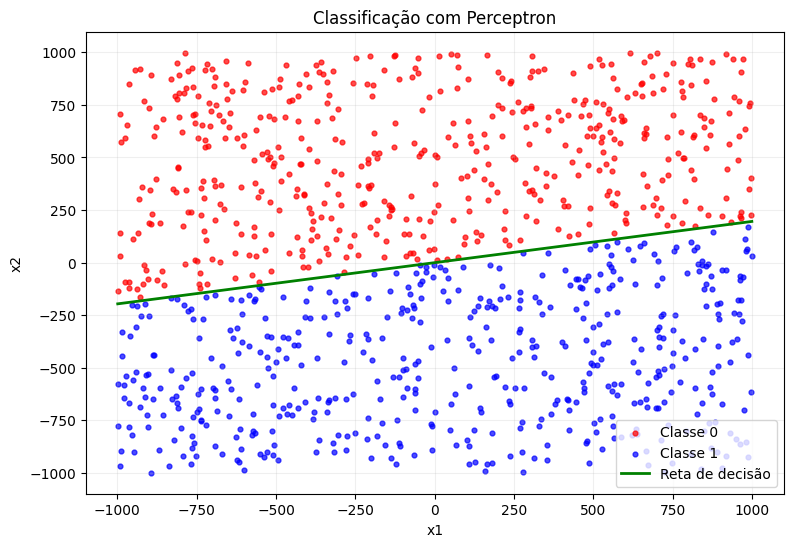

In [5]:

plt.figure(figsize=(9, 6))

plt.scatter(
    X[y == 0, 0], X[y == 0, 1],
    color="red", s=12, alpha=0.7, label="Classe 0"
)

plt.scatter(
    X[y == 1, 0], X[y == 1, 1],
    color="blue", s=12, alpha=0.7, label="Classe 1"
)

x_reta = np.linspace(X[:, 0].min(), X[:, 0].max(), 200)
y_reta = -(pesos[0] + pesos[1] * x_reta) / pesos[2]

plt.plot(x_reta, y_reta, color="green",
         linewidth=2, label="Reta de decisão")

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Classificação com Perceptron")
plt.legend()
plt.grid(alpha=0.2)
plt.show()
